<a href="https://colab.research.google.com/github/BB-lab24/lstm-microgrid/blob/main/LSTM_Microgrid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Short-term Prediction of Photovoltaic Power in a Microgrid Using LSTM Neural Network**


### **Problem-Solution Description**

The project is aimed at solviνg the issue of uncertainty when it comes to solar power production in a microgrid environment. In detail, we implement a Long Short-Term Memory neural network that is fed with historical meteorological data (such as radiation and temperature), in order to predict the power production of the grid's solar panels in the near future. The model's predictions constitute the critical tool needed for the microgrid's smart control. They allow the most efficient and optimized management of energy storage (batteries located in the grid), while ensuring and maintaining the robustness of the system. The ultimate consequence and goal that is achieved is limiting dependency from a main central grid and minimizing functional costs.
#
----
### **Chosen Dataset**
The selected dataset is taken from the Photovoltaic Geographical Information System (PVGIS), an official site from the European Union. PVGIS provides information on solar radiation and photovoltaic system performance for any location in the world. Our data is in CSV format and the related file contains around 166.000 hourly taken measurements, from 2005 to 2023. The data types we are going to work with are the following:

* P: Power PV (Watt) -> target, what the model predicts

* Gb(i): Direct Radiation (W/m^2)

* Gd(i): Diffuse Radiation (W/m^2)

* Gr(i): Reflected Radiation (w/m^2)

* H_sun: Sun Height (degrees)

* T2m: Temperature 2m. (Celcius)

* WS10m Wind Velocity 10m (m/s)
#

Power PV is what we want the model to predict, and the rest of the data types and their values are features that shape the values of each prediction.

Finally, the foretold measurements are for Thessaloniki in Greece, and the exact conditions are specified through these metadata: Slope is 35 degrees, Azimuth is 2 degrees, installed peak PV power is 1kWp, system loss haw been set to 14%, and the PV technology is Crystalline Silicon.



#
---
### **Project's Layout**

The project is structured in the following order (sections):

1. Data Loading and Preprocessing
2. Feature Engineering
3. LSTM Model
4. Model Prediction and Evaluation
5. Microgrid EMS
6. Visualizations

## Data Loader and Preprocessing
---

First and foremost, the dataset needs to be loaded from the related CSV file which is stored in our Google Drive, so we mount it to Google Colab. Afterwards, we make sure the data is numerical and time is set as the index of the DataFrame. Every column is then renamed so that they become easily readable.  

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')


# Load data from drive
df = pd.read_csv('/content/drive/MyDrive/hourly_meteo_data.csv', skiprows=10, on_bad_lines='skip')

# Make them the same data type
df['P'] = pd.to_numeric(df['P'], errors='coerce')
df['time'] = pd.to_datetime(df['time'], format='%Y%m%d:%H%M', errors='coerce')

# Remove missing values or NaN
df.dropna(subset=['time'], inplace=True)

# Index
df.set_index('time', inplace=True)

# Rename columns
df = df.rename(columns={
    "P": "Power",
    "Gb(i)": "Direct_Rad.",
    "Gd(i)": "Diffuse_Rad.",
    "Gr(i)": "Reflected_Rad.",
    "H_sun": "Sun_Height",
    "T2m": "Temperature(2m)",
    "WS10m": "Wind_Velocity(10m)"
})

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_790/690386150.py:7: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/hourly_meteo_data.csv', skiprows=10, on_bad_lines='skip')


,Power,Direct_Rad.,Diffuse_Rad.,Reflected_Rad.,Sun_Height,Temperature(2m),Wind_Velocity(10m),Int
time,,,,,,,,
2005-01-01 00:10:00,0.0,0.0,0.0,0.0,0.0,4.19,2.07,0.0
2005-01-01 01:10:00,0.0,0.0,0.0,0.0,0.0,4.01,1.72,0.0
2005-01-01 02:10:00,0.0,0.0,0.0,0.0,0.0,3.86,1.52,0.0
2005-01-01 03:10:00,0.0,0.0,0.0,0.0,0.0,3.83,1.45,0.0
2005-01-01 04:10:00,0.0,0.0,0.0,0.0,0.0,3.86,1.45,0.0


Next, we check to see how many null values (NaN) we have in each column in order to remove them or fill them accordingly. Luckily there is none.

In [ ]:
# Spot null values
df.isnull().sum()


,0
Power,0
Direct_Rad.,0
Diffuse_Rad.,0
Reflected_Rad.,0
Sun_Height,0
Temperature(2m),0
Wind_Velocity(10m),0
Int,0


Using the ***describe()*** method we move into the exploratory data analysis part, where we try to make sense of our meteorological data. We immediately see that the last column, "Int", is nothing but zeroes so we remove it because it will have no effect on the model's predictions. We see that the power's mean value is approximately 166W and has a max 929W, logical for a 1kWp system. Moreover, the median is zero as the production is also zero at night. That means that we have no need for the night measurements (the values related to Sun_Height <= 0), so we choose to keep only the day values later on.

In [ ]:
df.describe()

,Power,Direct_Rad.,Diffuse_Rad.,Reflected_Rad.,Sun_Height,Temperature(2m),Wind_Velocity(10m),Int
count,166536.000000,166536.000000,166536.000000,166536.000000,166536.000000,166536.000000,166536.000000,166536.0
mean,166.164455,144.431842,67.729467,3.382057,15.297617,15.059602,1.832716,0.0
std,248.616678,247.753987,88.958518,4.996129,20.344258,8.264889,1.067012,0.0
min,0.000000,0.000000,0.000000,0.000000,-2.240000,-11.080000,0.000000,0.0
25%,0.000000,0.000000,0.000000,0.000000,0.000000,8.590000,1.100000,0.0
50%,0.000000,0.000000,0.000000,0.000000,0.000000,14.940000,1.590000,0.0
75%,283.712500,208.382500,137.940000,5.830000,28.200000,21.920000,2.280000,0.0
max,929.750000,963.910000,439.020000,18.400000,72.320000,37.940000,9.860000,0.0


Before we make any of the changes said above, we take a glimpse of the power production during a week of a summer. The bell like shape of the graph is noticeable and expected, as the production hits it's peak at noon and then gradually drops and becomes zero at night. The most important thing here is shown in 5th and 6th of July where we notice flunctuations: this is exactly the kind of issue, that is uncertainty, we mentioned in the problem's description. This is what we want to teach the model to predict.

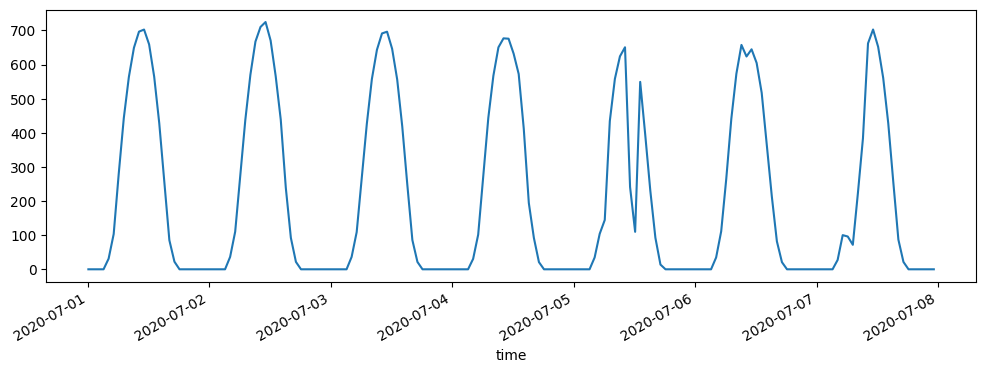

In [ ]:
import matplotlib.pyplot as plt

# Remove "Int" column
df = df.drop(columns=['Int'])

# Show example
df['Power']['2020-07-01':'2020-07-07'].plot(
    kind="line",
    figsize=(12, 4)
)

plt.show()

In [ ]:
# Keep only the day values
df = df[df['Sun_Height'] > 0]

df.shape

(80854, 7)

## Feature Engineering
---

In this part, we need to transform the meteo data in order for the LSTM model to process them in the most efficient way possible. First, we add to the main DataFrame two additional columns(features), one for the hours and one for the months, so that the model knows the chronological position.

In [ ]:
df['hour'] = df.index.hour
df['month'] = df.index.month

df.head()

,Power,Direct_Rad.,Diffuse_Rad.,Reflected_Rad.,Sun_Height,Temperature(2m),Wind_Velocity(10m),hour,month
time,,,,,,,,,
2005-01-01 07:10:00,54.38,22.18,54.21,1.17,11.01,3.62,1.38,7,1
2005-01-01 08:10:00,50.99,0.00,72.66,1.46,18.36,4.69,1.45,8,1
2005-01-01 09:10:00,89.87,2.03,114.73,2.32,23.59,5.68,1.72,9,1
2005-01-01 10:10:00,292.12,124.65,215.62,4.96,26.16,6.50,1.86,10,1
2005-01-01 11:10:00,133.81,10.01,156.13,3.19,25.72,7.12,1.86,11,1


Next, we need to normalize our data as we observe that most features of the DataFrame have very different scales between them. In the end, we every value of each column is transformed into a number between 0 and 1. This is only temporary and later the original values will retake their place.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Normalize data
scaler = MinMaxScaler()


split_idx = int(len(df) * 0.8)

# 1. Μαθαίνουμε τα min/max (fit) ΜΟΝΟ από το πρώτο 80% για να αποφύγουμε το leakage
scaler.fit(df.iloc[:split_idx])

# 2. Εφαρμόζουμε την κλίμακα (transform) σε ΟΛΟ το dataframe
scaled_data = scaler.transform(df)

# Φτιάχνουμε το df_scaled ακριβώς όπως το είχες, ώστε να μη χαλάσει τίποτα παρακάτω
df_scaled = pd.DataFrame(scaled_data, columns=df.columns, index=df.index)

df_scaled.describe()


,Power,Direct_Rad.,Diffuse_Rad.,Reflected_Rad.,Sun_Height,Temperature(2m),Wind_Velocity(10m),hour,month
count,80854.000000,80854.000000,80854.000000,80854.000000,80854.000000,80854.000000,80854.000000,80854.000000,80854.000000
mean,0.368111,0.308626,0.316421,0.381862,0.435539,0.583646,0.199022,0.487155,0.494587
std,0.278496,0.295074,0.180964,0.282718,0.255654,0.166895,0.115548,0.270305,0.291158
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.090218,0.014369,0.184613,0.122045,0.234302,0.455528,0.111562,0.230769,0.272727
50%,0.324802,0.230535,0.317783,0.335899,0.399447,0.593431,0.174442,0.461538,0.454545
75%,0.636004,0.593287,0.402752,0.610225,0.621438,0.721746,0.258621,0.692308,0.727273
max,1.000000,1.000000,1.000000,1.010445,1.000000,1.000000,1.000000,1.000000,1.000000


The LSTM  model needs to be fed a series of consecutive steps (samples) in order to make a prediction, for example we give as input  24 hourly data and predicts the Power's next value. That is called a **window** and we can assign whatever value fits us best. We begin with 24.

In [ ]:
import numpy as np

def create_sequences(data, target_col, window=24):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i])
        y.append(data[i, target_col])
    return np.array(X), np.array(y)


target_col = df_scaled.columns.get_loc('Power')
X, y = create_sequences(df_scaled.values, target_col, window=24)
print(X.shape, y.shape)

(80830, 24, 9) (80830,)


The result of the above is that we have separated the dataset in two main arrays: one with 80.830 samples where each one is described by 24 hourly steps and 9 features (X), and one with our Power target values (y). At last, we split the dataset into train test sets.

In [ ]:
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
print(X_train.shape, X_test.shape)

(64664, 24, 9) (16166, 24, 9)


## LSTM Model
---

The LSTM model we implement consists of three main layers: the **LSTM layer** that learns the time patterns, the **dropout layer** that prevents overfitting by disabling at random 20% of neurons, and the **dense layer** thet produces the prediction P (power).  We make use of the adam optimizer, and choose the MSE as a loss metric.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential()
model.add(LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dropout(0.2))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mse')
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

We then train the model for 20 epochs, creating mini batches of 64, and making a validation set using the 10% of the dataset to check for overfitting.  

In [ ]:
history = model.fit(X_train, y_train, epochs=20, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step - loss: 0.0183 - val_loss: 0.0109
Epoch 2/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - loss: 0.0116 - val_loss: 0.0099
Epoch 3/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - loss: 0.0107 - val_loss: 0.0091
Epoch 4/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - loss: 0.0101 - val_loss: 0.0090
Epoch 5/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - loss: 0.0097 - val_loss: 0.0091
Epoch 6/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - loss: 0.0095 - val_loss: 0.0086
Epoch 7/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - loss: 0.0093 - val_loss: 0.0085
Epoch 8/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - loss: 0.0093 - val_loss: 0.0085
Epoch 9/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - loss: 0.0092 - val_loss: 0.0085
Epoch 10/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - loss: 0.0092 - val_loss: 0.0085
Epoch 11/20
910/910 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - loss: 0.0091 - val_loss: 0.0084
Epoch 12/20
910/910 ━━━━━━━━━━

We plot the loss results from the trainig and the validation sets for comparison. The train loss decreases to 0.0088, while the validation loss follows the latter and drops to 0.0081, so there is no overfitting.

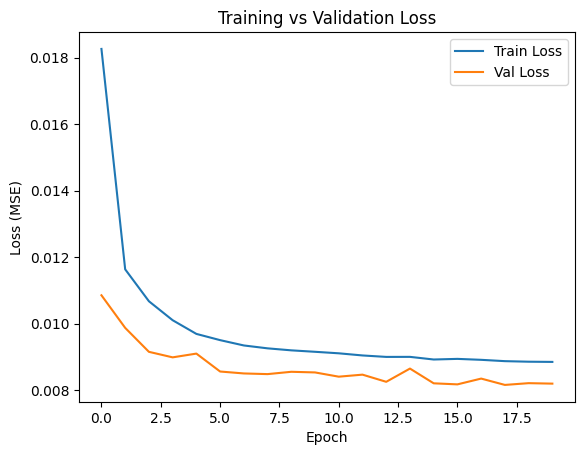

In [ ]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Training vs Validation Loss')
plt.show()

## Model Predictions and Evaluation
---

In this section, we put the model to the test and see how well it generalizes on the unseen data. We measure the model's performance by calculating the Mean Absolute Error (MAE) and the Root Mean Square Error (RMSE).

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Model makes predictions
y_pred = model.predict(X_test)

# Evaluate predictions
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f'MAE: {mae:.4f}')
print(f'RMSE: {rmse:.4f}')

506/506 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
MAE: 0.0514
RMSE: 0.0905


The results are very good, as MAE = 0.0526 means that the model makes false predictions on average 5% of the scale. Our data were scaled until this time, so now we inverse transform them to see the real data values.

In [ ]:
import numpy as np

dummy_pred = np.zeros((len(y_pred), df_scaled.shape[1]))
dummy_pred[:, 0] = y_pred.flatten()
y_pred_watts = scaler.inverse_transform(dummy_pred)[:, 0]

dummy_test = np.zeros((len(y_test), df_scaled.shape[1]))
dummy_test[:, 0] = y_test
y_test_watts = scaler.inverse_transform(dummy_test)[:, 0]

mae_w = mean_absolute_error(y_test_watts, y_pred_watts)
rmse_w = np.sqrt(mean_squared_error(y_test_watts, y_pred_watts))
print(f'MAE: {mae_w:.2f} W')
print(f'RMSE: {rmse_w:.2f} W')

MAE: 47.83 W
RMSE: 84.13 W


Now we see that in a 1kWp (max ~930W) system we have the following:

* MAE: 48.9 W, which means that on average we have approximately 49W divergence in our predictions (5.3% of peak).

* RMSE: 83.9 W, which means the biggest mistakes reach approximately 84W, mainly when it comes to sudden weather changes (e.g. cloudy weather).

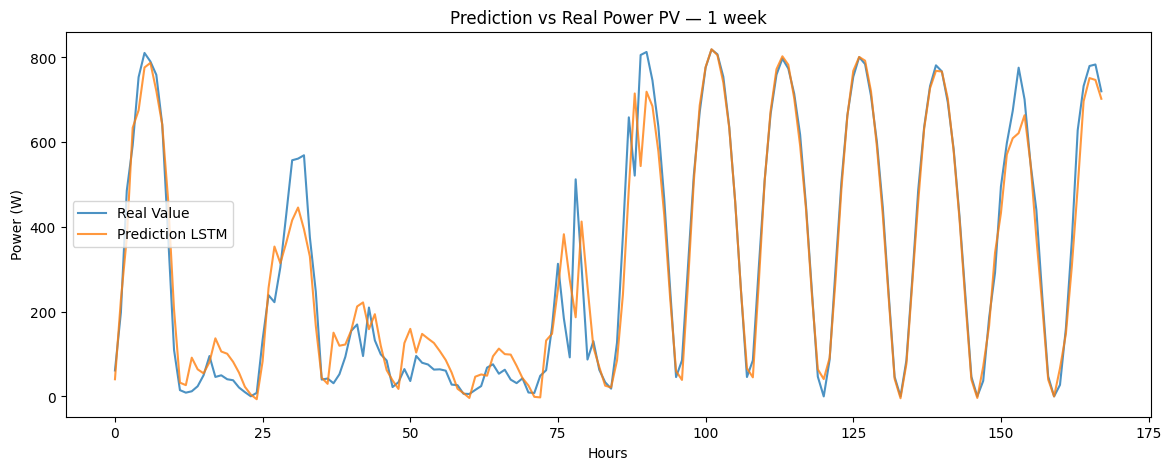

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(y_test_watts[:168], label='Real Value', alpha=0.8)
plt.plot(y_pred_watts[:168], label='Prediction LSTM', alpha=0.8)
plt.legend()
plt.xlabel('Hours')
plt.ylabel('Power (W)')
plt.title('Prediction vs Real Power PV — 1 week')
plt.show()

By plotting the prediction vs the real values for a time period of one week, we conclude the following:

* On sunny days (bell shaped parts of the graph) the LSTM matches nearly perfectly the real values.

* On cloudy days the LSTM is having a little trouble as expected, because the appearance of clouds is difficult to predict.

Now, in order to make better sense of our data we build a simple baseline model to compare the previous results. The comparison will show the differences between using a predictive neural network with LSTM in the grid and not.  

In [ ]:
y_persistence = X_test[:, -1, 0]

dummy_pers = np.zeros((len(y_persistence), df_scaled.shape[1]))
dummy_pers[:, 0] = y_persistence
y_pers_watts = scaler.inverse_transform(dummy_pers)[:, 0]

mae_pers = mean_absolute_error(y_test_watts, y_pers_watts)
rmse_pers = np.sqrt(mean_squared_error(y_test_watts, y_pers_watts))
print(f'Persistence MAE: {mae_pers:.2f} W')
print(f'Persistence RMSE: {rmse_pers:.2f} W')
print(f'LSTM MAE: {mae_w:.2f} W')
print(f'LSTM RMSE: {rmse_w:.2f} W')

Persistence MAE: 114.99 W
Persistence RMSE: 146.86 W
LSTM MAE: 47.83 W
LSTM RMSE: 84.13 W


From the above results, we immediately conclude that using an LSTM model is pretty helpfull and mandatory if you will. We have nearly 57% improvement when it comes to the MAE, and 43% in the RMSE. The results are also plotted for better understanding of the difference.

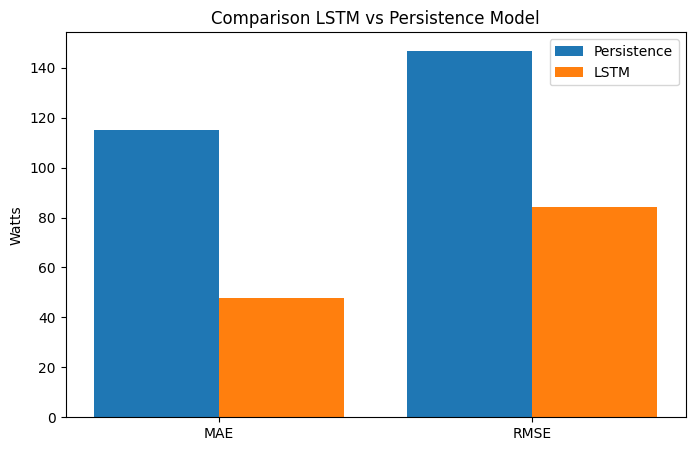

In [ ]:
labels = ['MAE', 'RMSE']
lstm_vals = [mae_w, rmse_w]
pers_vals = [mae_pers, rmse_pers]

x = np.arange(len(labels))
plt.figure(figsize=(8, 5))
plt.bar(x - 0.2, pers_vals, 0.4, label='Persistence')
plt.bar(x + 0.2, lstm_vals, 0.4, label='LSTM')
plt.ylabel('Watts')
plt.title('Comparison LSTM vs Persistence Model')
plt.xticks(x, labels)
plt.legend()
plt.show()

## Microgrid EMS
---

The Microgrid EMS controller is rule based and we suppose it consists of the following: PV panels, a battery, a load (consumption), and a connection with the main grid.

Every hour the controller comes across these decisions:

1. If PV > load --> the surplus charges the battery

2. If the battery is fully charged --> sell to the main grid

3. If PV < load --> discharge battery for the deficit

4. If the battery empties --> buy from the grid

Firstly, we build a consumption load based on the fact that a standard household consumes on average 300-500 W during the day. We use as boundaries 150W to 500W.

In [ ]:
np.random.seed(42)
load = 300 + 100 * np.sin(np.linspace(0, 20*np.pi, len(y_pred_watts))) + np.random.normal(0, 30, len(y_pred_watts))
load = np.clip(load, 150, 500)

Next, we move on to the controller by setting the battery's charachteristics and then implementing the foretold rules.

In [ ]:
battery_capacity = 2000  # Wh max capacity
soc = 1000               # Wh initial charge (50%)
soc_min = 200            # Wh min (10%)
soc_max = 1800           # Wh max (90%)

soc_history = []
grid_buy = []
grid_sell = []

for t in range(len(y_pred_watts)):
    pv = y_pred_watts[t]
    demand = load[t]
    surplus = pv - demand

    if surplus > 0:
        # Surplus -> charge battery
        charge = min(surplus, soc_max - soc)
        soc += charge
        sell = surplus - charge
        grid_sell.append(sell)
        grid_buy.append(0)
    else:
        # Deficit → discharge battery
        deficit = -surplus
        discharge = min(deficit, soc - soc_min)
        soc -= discharge
        buy = deficit - discharge
        grid_buy.append(buy)
        grid_sell.append(0)

    soc_history.append(soc)

We also make some plots to visualize the microgrid's operations:

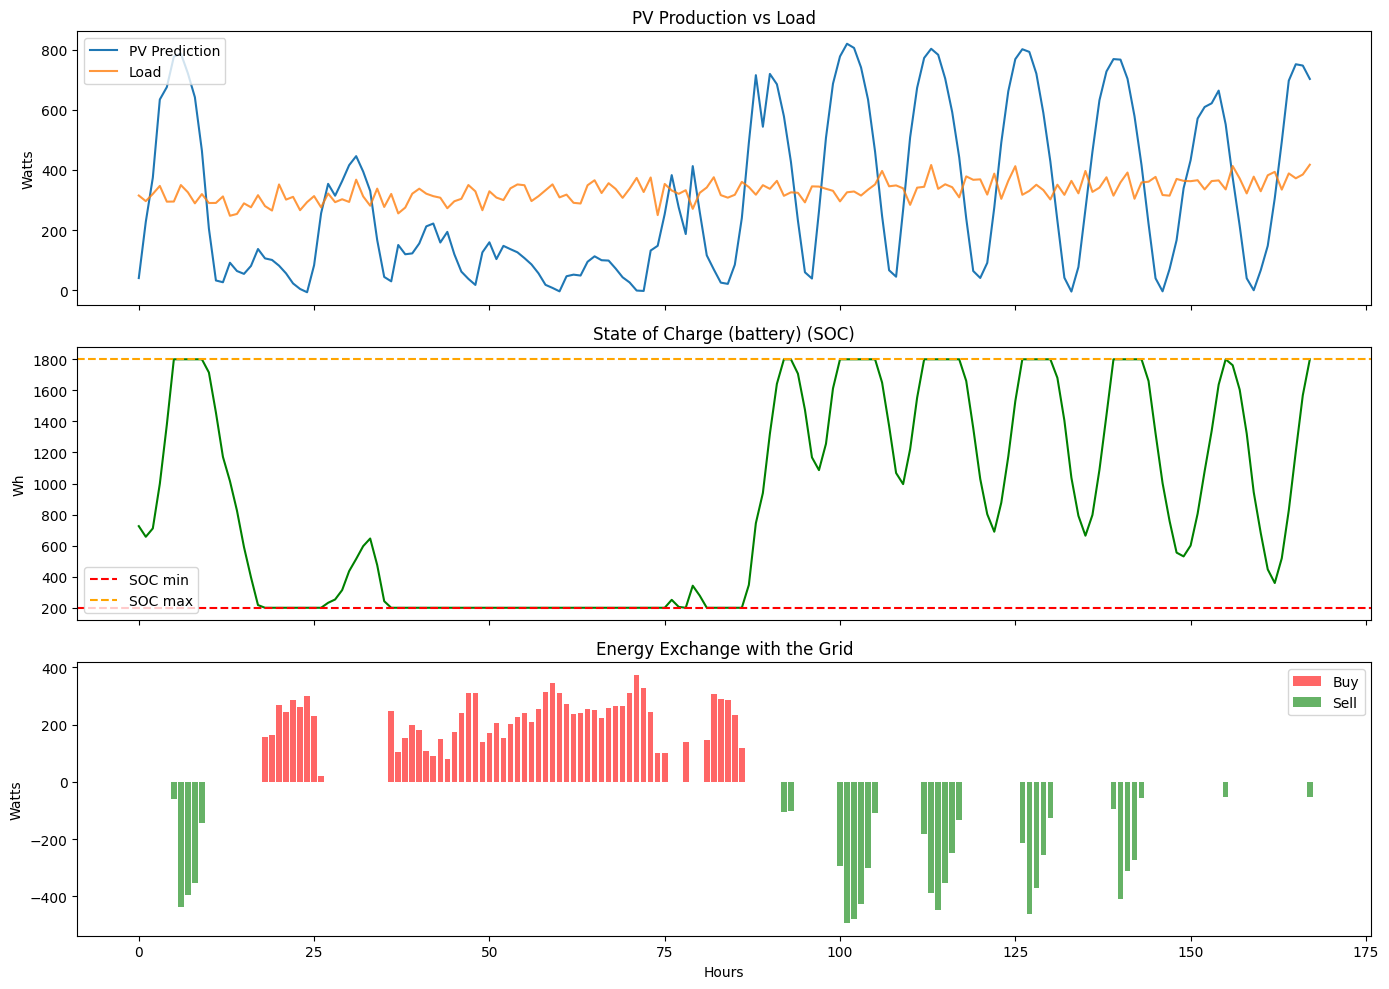

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
hours = range(168)  # 1 week

# 1. PV vs Load
axes[0].plot([y_pred_watts[i] for i in hours], label='PV Prediction')
axes[0].plot([load[i] for i in hours], label='Load', alpha=0.8)
axes[0].set_ylabel('Watts')
axes[0].set_title('PV Production vs Load')
axes[0].legend()

# 2. State of Charge (battery)
axes[1].plot([soc_history[i] for i in hours], color='green')
axes[1].axhline(y=soc_min, color='red', linestyle='--', label='SOC min')
axes[1].axhline(y=soc_max, color='orange', linestyle='--', label='SOC max')
axes[1].set_ylabel('Wh')
axes[1].set_title('State of Charge (battery) (SOC)')
axes[1].legend()

# 3. Buy/Sell from the main grid
axes[2].bar(hours, [grid_buy[i] for i in hours], color='red', alpha=0.6, label='Buy')
axes[2].bar(hours, [-grid_sell[i] for i in hours], color='green', alpha=0.6, label='Sell')
axes[2].set_ylabel('Watts')
axes[2].set_xlabel('Hours')
axes[2].set_title('Energy Exchange with the Grid')
axes[2].legend()

plt.tight_layout()
plt.show()

In the first graph, we see that when the blue line (PV) is above the yellow one (load), there is a surplus, and when it is lower we have a deficit, especially the cloudy days (hours 25 to 75).

In the second plot, we observe that the battery charges on sunny days and discharges on the rest. It is notable that it remains in-between the limits shown.

In the last graph, we can see in the first days, and a little bit after, that the microgrid buys from the main grid due to bad weather. But, in the last days, we see the exact opposite, the microgrid sells to the main grid. This proves why predictions like these are valuable: the controller makes the best possible use of the PV production.


A  summary of the microgrid's controller results is shown bellow:

In [ ]:
total_buy = sum(grid_buy)
total_sell = sum(grid_sell)
total_load = sum(load)
self_sufficiency = (1 - total_buy / total_load) * 100

print(f'Total buy form the main grid: {total_buy:.0f} Wh')
print(f'Total sell to the main grid: {total_sell:.0f} Wh')
print(f'self-sufficiency: {self_sufficiency:.1f}%')

Total buy form the main grid: 459695 Wh
Total sell to the main grid: 1244407 Wh
self-sufficiency: 90.5%


## Sensor Noise Robustness
---

In a real-world Microgrid, sensor measurements (e.g., radiation, temperature) are not always perfect. They often contain noise due to dust, malfunctions, or interference. Here, we simulate this condition by adding random noise (normally distributed) to the test data (X_test) and evaluate how robust our LSTM model is.

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error

# Simulate noisy data
noise_factor = 0.05

# Adding random normal noise to our data
X_test_noisy = X_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=X_test.shape)

# We restrict our values in [0, 1] like the MinMaxScaler
X_test_noisy = np.clip(X_test_noisy, 0., 1.)

# Prediction on noisy data
predictions_noisy = model.predict(X_test_noisy)
mse_noisy = mean_squared_error(y_test, predictions_noisy)

print(f"Mean Square Error (MSE) on data from noisy sensors: {mse_noisy:.5f}")

506/506 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Mean Square Error (MSE) on data from noisy sensors: 0.00932


## Online Learning
----

In a smart grid environment, new data is continuously generated. Instead of training the model only once, we can update (retrain) it gradually as new measurements arrive. This process is called online learning and demonstrates that the model can adapt to seasonal changes or equipment aging.

In [ ]:
# We use X_test as the new data arriving gradually
chunk_size = 720  # We assume that we gather a month's data
online_epochs = 1 # Re-training for few epochs for fast adjustment

print("Online Learning Starting...")

# Gradually feeding the model
for i in range(0, len(X_test), chunk_size):
    X_chunk = X_test[i:i+chunk_size]
    y_chunk = y_test[i:i+chunk_size]

    # Update model's weights with the new data
    model.fit(X_chunk, y_chunk, epochs=online_epochs, batch_size=64, verbose=0)

    if i % (chunk_size * 4) == 0:
        print(f"The model adjusted to the new {i + len(X_chunk)} samples...")

# Final evaluation is done on the same data for comparison
# ideally we wou;d have a different 'future_test' set)
predictions_online = model.predict(X_test)
mse_online = mean_squared_error(y_test, predictions_online)
print(f"Final MSE after Online Learning: {mse_online:.5f}")

Online Learning Starting...
The model adjusted to the new 720 samples...
The model adjusted to the new 3600 samples...
The model adjusted to the new 6480 samples...
The model adjusted to the new 9360 samples...
The model adjusted to the new 12240 samples...
The model adjusted to the new 15120 samples...
506/506 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Final MSE after Online Learning: 0.00832


## Weather Forecast Uncertainty
---

The model requires information such as Direct Radiation (Direct_Rad.), Temperature, and Wind Velocity. In reality, to predict "tomorrow", we do not have perfect measurements, but rather weather forecasts. Here, we simulate the use of weather forecasts by adding higher uncertainty only to the meteorological features.

## Final Simulation
---

In [ ]:
X_test_forecast = X_test.copy()

# Erros for weather predictions are usually higher than those of a local sensor
forecast_error_factor = 0.15

# We add noise only to meteorological features (index 1 to 6)

for feature_idx in range(1, 7):
    # Noise production for the specific feature
    noise = forecast_error_factor * np.random.normal(loc=0.0, scale=1.0, size=X_test_forecast[:, :, feature_idx].shape)
    X_test_forecast[:, :, feature_idx] += noise

# We clip again to [0, 1]
X_test_forecast = np.clip(X_test_forecast, 0., 1.)

# Calculate production predictions using the not so perfect weather forecast
predictions_forecast = model.predict(X_test_forecast)
mse_forecast = mean_squared_error(y_test, predictions_forecast)

print(f"MSE using uncertain Meteorological Predictions: {mse_forecast:.5f}")

506/506 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
MSE using uncertain Meteorological Predictions: 0.01336


Starting Online EMS Simulation...
Simulation Completed!


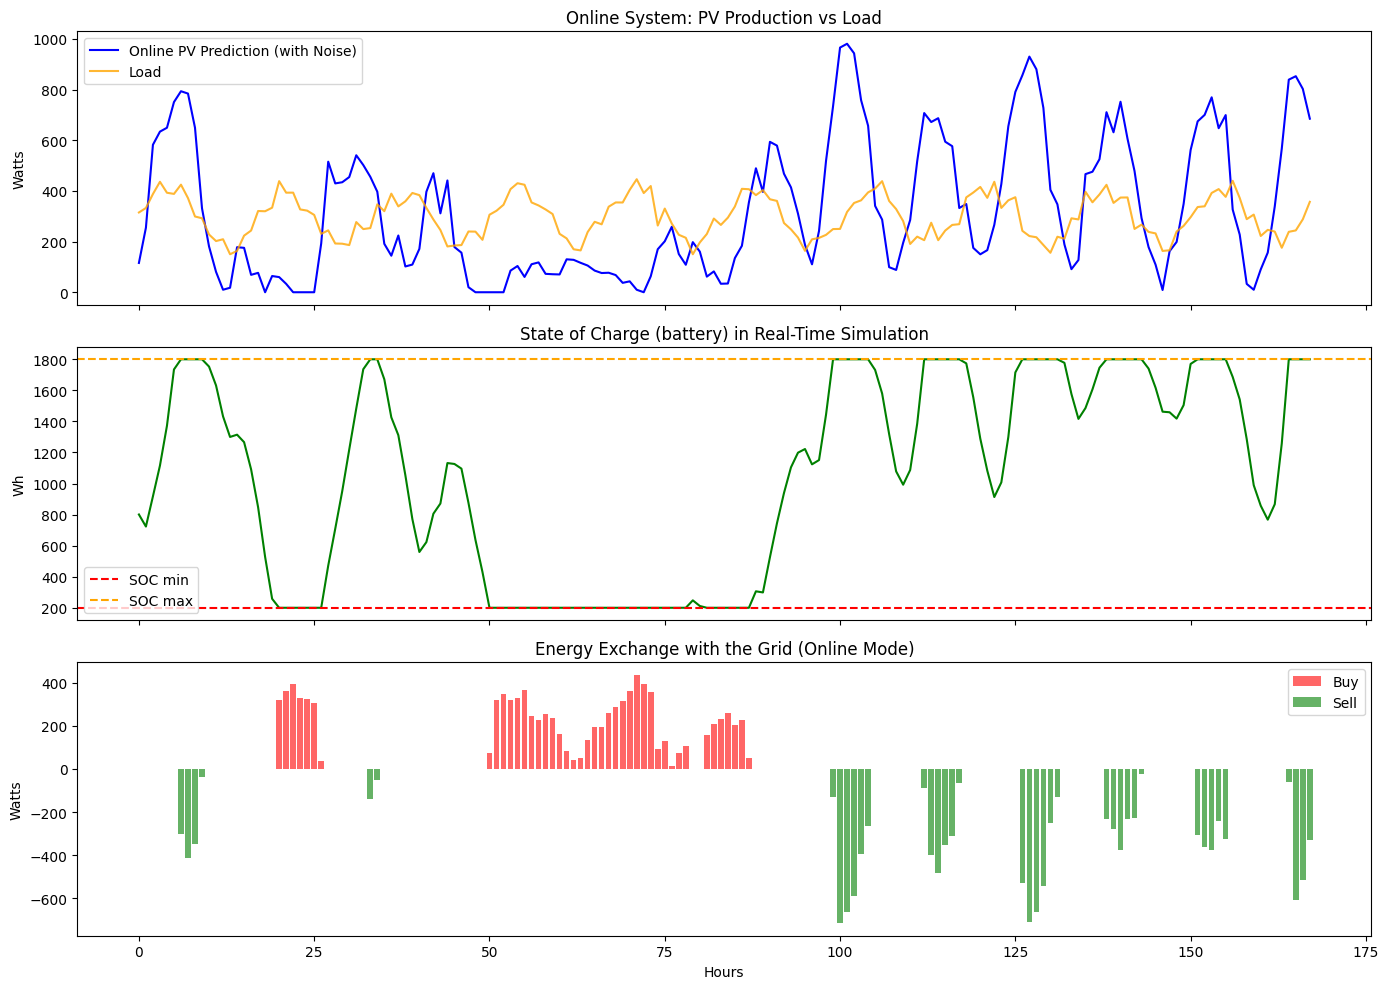

In [ ]:
# ==============================================================================
# FINAL CELL: Real-Time Microgrid Simulation with Online Learning & Noisy Forecasts
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

# 1. Προετοιμασία μεταβλητών EMS (όπως τα έχεις ήδη ορίσει)
battery_capacity = 2000     # Wh max capacity
soc = 1000                  # Wh initial charge (50%)
soc_min = 200               # Wh min (10%)
soc_max = 1800              # Wh max (90%)

soc_history_online = []
grid_buy_online = []
grid_sell_online = []
pv_predictions_online = []

# Παίρνουμε ένα μικρό δείγμα ημερών από το Test Set (π.χ. 1 εβδομάδα = 168 ώρες)
simulation_hours = 168

# Κάνουμε update το load list σε περίπτωση που το test set έχει διαφορετικό μέγεθος
np.random.seed(42)
load_online = 300 + 100 * np.sin(np.linspace(0, 20*np.pi, simulation_hours)) + np.random.normal(0, 30, simulation_hours)
load_online = np.clip(load_online, 150, 500)

# Το σφάλμα της πρόγνωσης που έχεις ήδη ορίσει
forecast_error_factor = 0.15

print("Starting Online EMS Simulation...")

# 2. Το Loop της πραγματικής ώρας (Hour-by-Hour)
for t in range(simulation_hours):

    # --- ΒΗΜΑ Α: Λήψη Αμφίβολης Πρόγνωσης Καιρού ---
    # Παίρνουμε τα πραγματικά δεδομένα της τρέχουσας ώρας (με το window=24)
    current_X_true = X_test[t:t+1].copy()
    current_y_true = y_test[t:t+1]

    # Προσθήκη θορύβου (προσομοίωση πρόγνωσης) στα μετεωρολογικά χαρακτηριστικά (indexes 1-6)
    current_X_forecast = current_X_true.copy()
    for feature_idx in range(1, 7):
        noise = forecast_error_factor * np.random.normal(loc=0.0, scale=1.0, size=current_X_forecast[:, :, feature_idx].shape)
        current_X_forecast[:, :, feature_idx] += noise

    current_X_forecast = np.clip(current_X_forecast, 0., 1.)

    # --- ΒΗΜΑ Β: Πρόβλεψη παραγωγής PV από το LSTM (με βάση την πρόγνωση) ---
    pred_scaled = model.predict(current_X_forecast, verbose=0)

    # Inverse transform για να βρούμε τα Watt (Επειδή έκανες MinMax σε όλο το DF,
    # πρέπει να φτιάξουμε ένα dummy array με 9 features για να κάνουμε σωστά το inverse).
    dummy = np.zeros((1, df_scaled.shape[1]))
    dummy[0, df_scaled.columns.get_loc('Power')] = pred_scaled[0, 0]
    pv_pred_watts = scaler.inverse_transform(dummy)[0, df_scaled.columns.get_loc('Power')]
    pv_pred_watts = max(0, pv_pred_watts) # Αποφυγή αρνητικής παραγωγής
    pv_predictions_online.append(pv_pred_watts)


    # --- ΒΗΜΑ Γ: Microgrid EMS Control (Μπαταρία) ---
    demand = load_online[t]
    surplus = pv_pred_watts - demand

    if surplus > 0:
        charge = min(surplus, soc_max - soc)
        soc += charge
        sell = surplus - charge
        grid_sell_online.append(sell)
        grid_buy_online.append(0)
    else:
        deficit = -surplus
        discharge = min(deficit, soc - soc_min)
        soc -= discharge
        buy = deficit - discharge
        grid_buy_online.append(buy)
        grid_sell_online.append(0)

    soc_history_online.append(soc)

    # --- ΒΗΜΑ Δ: Online Learning ---
    # Η ώρα πέρασε, ξέρουμε τον πραγματικό καιρό. Ενημερώνουμε το LSTM με τα True Data!
    model.train_on_batch(current_X_true, current_y_true)

print("Simulation Completed!")

# 3. Οπτικοποίηση των αποτελεσμάτων του Online Συστήματος
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
hours = range(simulation_hours)

# 1. PV vs Load
axes[0].plot(hours, pv_predictions_online, label='Online PV Prediction (with Noise)', color='blue')
axes[0].plot(hours, load_online, label='Load', color='orange', alpha=0.8)
axes[0].set_ylabel('Watts')
axes[0].set_title('Online System: PV Production vs Load')
axes[0].legend()

# 2. State of Charge (battery)
axes[1].plot(hours, soc_history_online, color='green')
axes[1].axhline(y=soc_min, color='red', linestyle='--', label='SOC min')
axes[1].axhline(y=soc_max, color='orange', linestyle='--', label='SOC max')
axes[1].set_ylabel('Wh')
axes[1].set_title('State of Charge (battery) in Real-Time Simulation')
axes[1].legend()

# 3. Buy/Sell from the main grid
axes[2].bar(hours, grid_buy_online, color='red', alpha=0.6, label='Buy')
axes[2].bar(hours, [-s for s in grid_sell_online], color='green', alpha=0.6, label='Sell')
axes[2].set_ylabel('Watts')
axes[2].set_xlabel('Hours')
axes[2].set_title('Energy Exchange with the Grid (Online Mode)')
axes[2].legend()

plt.tight_layout()
plt.show()